In [1]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

In [ ]:
df_train = pd.read_excel("两年训练集过采样.xlsx")
print(df_train.head())

In [ ]:
df_test = pd.read_excel("73平衡测试集.xlsx")
print(df_test.head(5))

In [4]:
# 特征和标签定义
X_train = df_train.drop(columns=['com_endow'])
y_train = df_train['com_endow']
X_test = df_test.drop(columns=['com_endow'])
y_test = df_test['com_endow']

In [45]:
# 设定XGBoost参数
params = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 20],
    'learning_rate': [0.01, 0.05],
    'subsample': [0.8, 0.9, 1],
    'scale_pos_weight': [2],  # 用于增加阳性样本识别代价
}

In [46]:
# 使用5折交叉验证进行超参数调优
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=77)
grid_search = GridSearchCV(XGBClassifier(), params, cv=kf, scoring='recall', n_jobs=-1)

# 进行网格搜索以找到最佳参数
grid_search.fit(X_train, y_train)

# 输出最佳参数
print("Best Parameters:", grid_search.best_params_)

# 使用最佳参数训练模型
best_model = grid_search.best_estimator_

Best Parameters: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 100, 'scale_pos_weight': 2, 'subsample': 0.9}


In [47]:
# 在测试集上进行预测
#y_pred = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:,1]
y_pred = (y_pred_proba > 0.4).astype(int)
# 评估模型性能
print("Test Set Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Test Set Accuracy: 0.6666666666666666
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.64      0.73       445
           1       0.46      0.72      0.56       191

    accuracy                           0.67       636
   macro avg       0.65      0.68      0.65       636
weighted avg       0.73      0.67      0.68       636



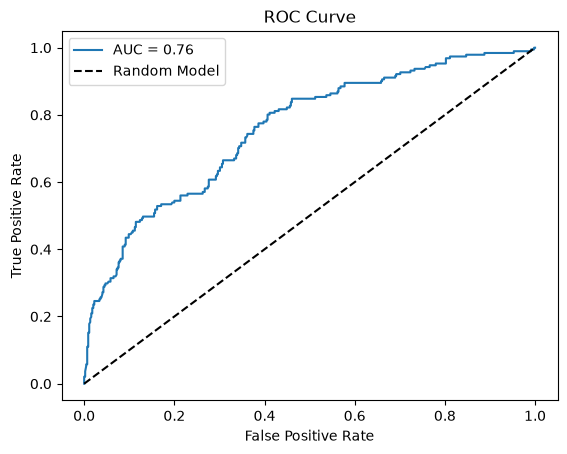

In [48]:
# 绘制ROC曲线
y_pred_proba = best_model.predict_proba(X_test)[:,1]
roc_auc = roc_auc_score(y_test, y_pred_proba)
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

plt.figure()
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0,1],[0,1],'k--',label='Random Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='best')
plt.show()

In [49]:
import shap

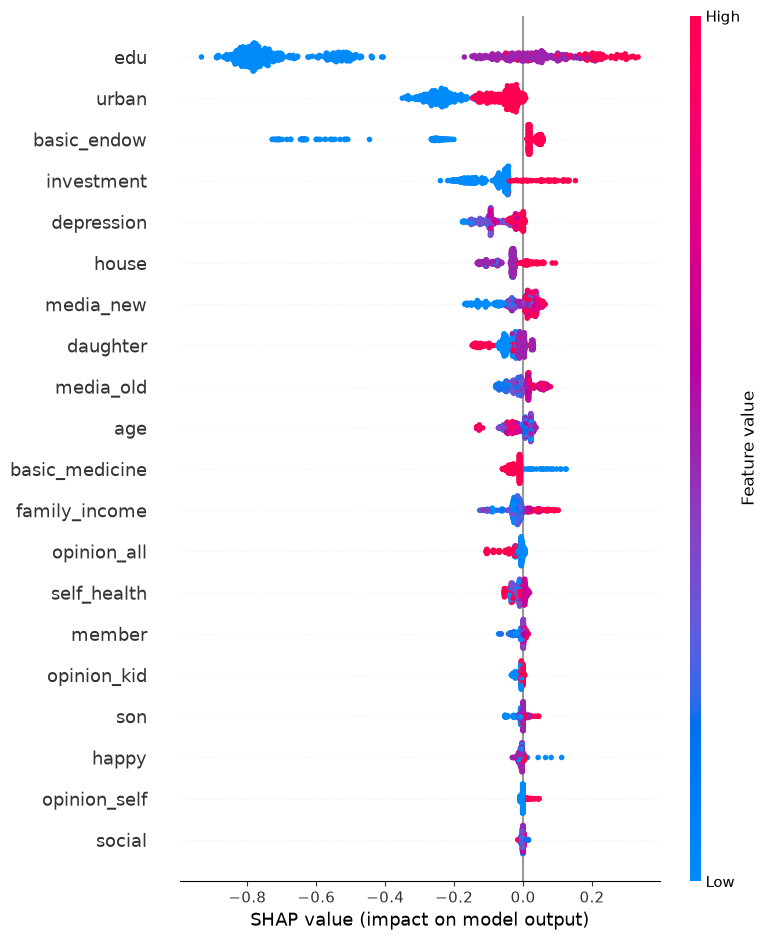

In [50]:
explainer = shap.Explainer(best_model)
shap_values = explainer(X_test)
shap.summary_plot(shap_values, X_test)

#最优模型，正负代价1:2， 7:3测试集  smote采样1  

In [31]:
#偏依赖图
from sklearn.inspection import PartialDependenceDisplay

# 将绘图数据中的整数列转换为浮点数
X_train_pdp = X_train.copy()
X_train_pdp = X_train_pdp.astype({
    col: "float64"
    for col in X_train_pdp.select_dtypes(include=["integer"]).columns
})

X_test_pdp = X_test.copy()
X_test_pdp = X_test_pdp.astype({
    col: "float64"
    for col in X_test_pdp.select_dtypes(include=["integer"]).columns
})

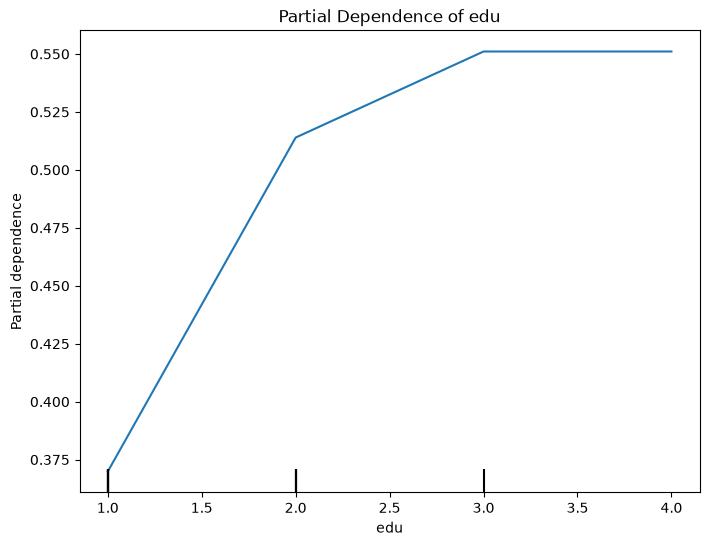

In [33]:
#edu
feature_idx = X_train_pdp.columns.get_loc('edu')

# Plot the partial dependence plot
fig, ax = plt.subplots(figsize=(8, 6))

# In versions prior to 0.24, you may use plot_partial_dependence
# plot_partial_dependence(best_model, X_train, [feature_idx], ax=ax)

# Using PartialDependenceDisplay (available in newer versions of sklearn)
PartialDependenceDisplay.from_estimator(best_model, X_test_pdp, [feature_idx], ax=ax)

plt.title(f'Partial Dependence of {X_train_pdp.columns[feature_idx]}')
plt.show()

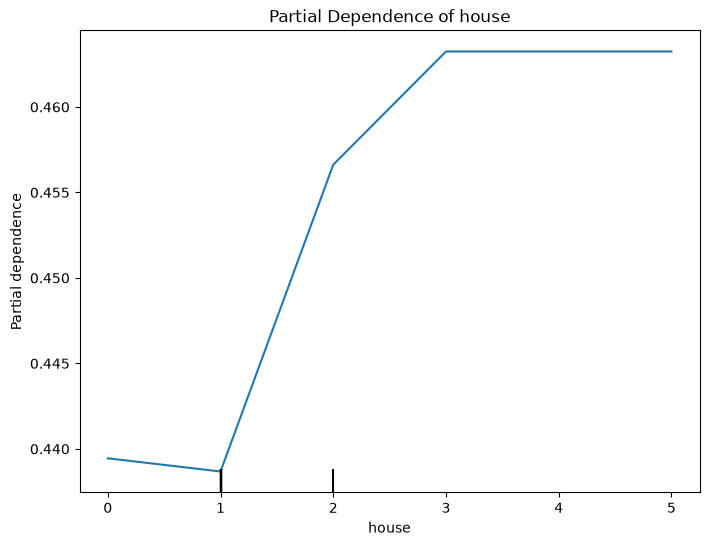

In [34]:
#house
feature_idx = X_train_pdp.columns.get_loc('house')

# Plot the partial dependence plot
fig, ax = plt.subplots(figsize=(8, 6))

# In versions prior to 0.24, you may use plot_partial_dependence
# plot_partial_dependence(best_model, X_train, [feature_idx], ax=ax)

# Using PartialDependenceDisplay (available in newer versions of sklearn)
PartialDependenceDisplay.from_estimator(best_model, X_test_pdp, [feature_idx], ax=ax)

plt.title(f'Partial Dependence of {X_train_pdp.columns[feature_idx]}')
plt.show()

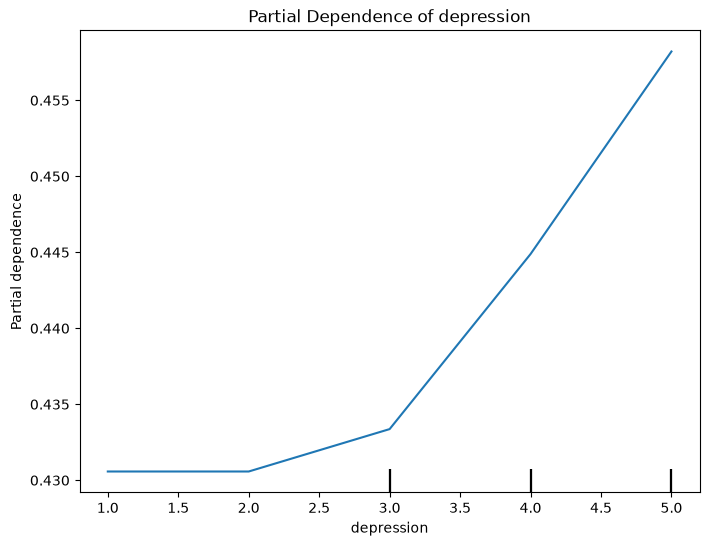

In [35]:
#depression
feature_idx = X_train_pdp.columns.get_loc('depression')

# Plot the partial dependence plot
fig, ax = plt.subplots(figsize=(8, 6))

# In versions prior to 0.24, you may use plot_partial_dependence
# plot_partial_dependence(best_model, X_train, [feature_idx], ax=ax)

# Using PartialDependenceDisplay (available in newer versions of sklearn)
PartialDependenceDisplay.from_estimator(best_model, X_test_pdp, [feature_idx], ax=ax)

plt.title(f'Partial Dependence of {X_train_pdp.columns[feature_idx]}')
plt.show()

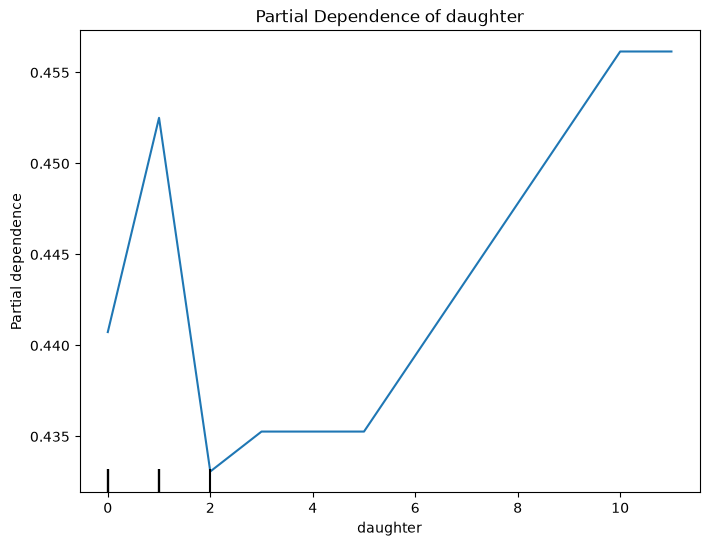

In [36]:
#daughter
feature_idx = X_train_pdp.columns.get_loc('daughter')

# Plot the partial dependence plot
fig, ax = plt.subplots(figsize=(8, 6))

# In versions prior to 0.24, you may use plot_partial_dependence
# plot_partial_dependence(best_model, X_train, [feature_idx], ax=ax)

# Using PartialDependenceDisplay (available in newer versions of sklearn)
PartialDependenceDisplay.from_estimator(best_model, X_test_pdp, [feature_idx], ax=ax)

plt.title(f'Partial Dependence of {X_train_pdp.columns[feature_idx]}')
plt.show()

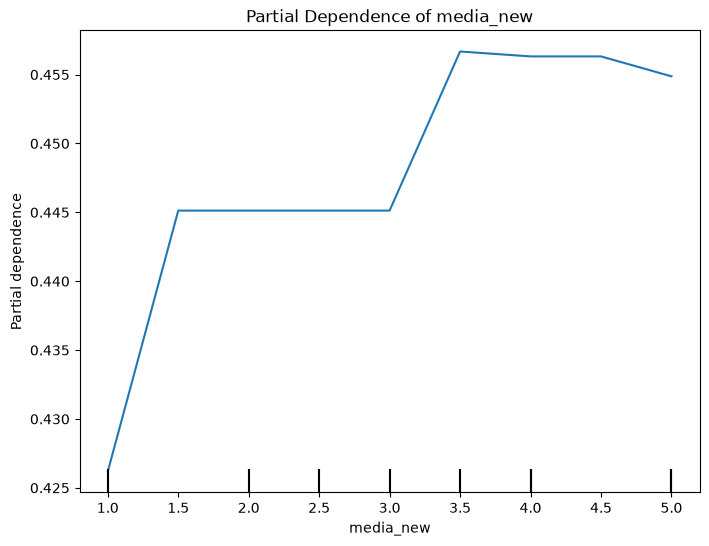

In [37]:
#media_new
feature_idx = X_train_pdp.columns.get_loc('media_new')

# Plot the partial dependence plot
fig, ax = plt.subplots(figsize=(8, 6))

# In versions prior to 0.24, you may use plot_partial_dependence
# plot_partial_dependence(best_model, X_train, [feature_idx], ax=ax)

# Using PartialDependenceDisplay (available in newer versions of sklearn)
PartialDependenceDisplay.from_estimator(best_model, X_test_pdp, [feature_idx], ax=ax)

plt.title(f'Partial Dependence of {X_train_pdp.columns[feature_idx]}')
plt.show()

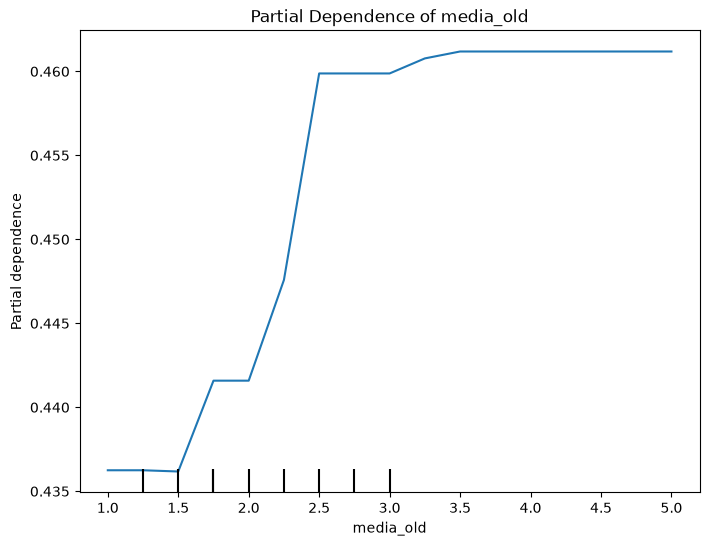

In [38]:
#media_old
feature_idx = X_train_pdp.columns.get_loc('media_old')

# Plot the partial dependence plot
fig, ax = plt.subplots(figsize=(8, 6))

# In versions prior to 0.24, you may use plot_partial_dependence
# plot_partial_dependence(best_model, X_train, [feature_idx], ax=ax)

# Using PartialDependenceDisplay (available in newer versions of sklearn)
PartialDependenceDisplay.from_estimator(best_model, X_test_pdp, [feature_idx], ax=ax)

plt.title(f'Partial Dependence of {X_train_pdp.columns[feature_idx]}')
plt.show()

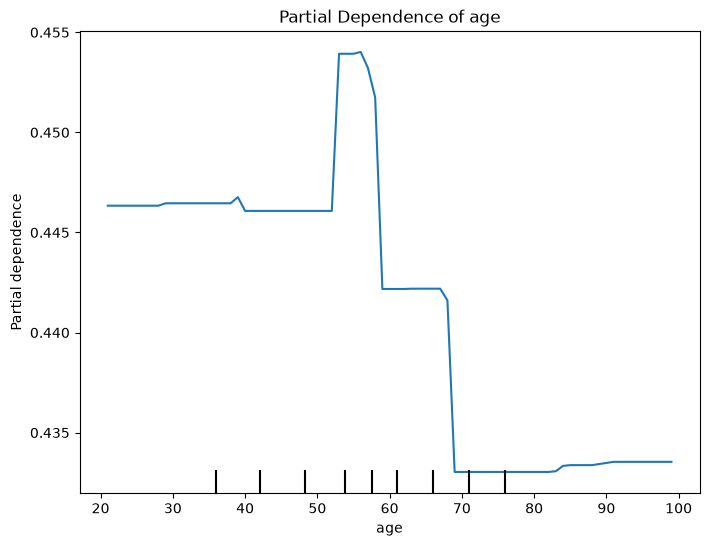

In [39]:
#age
feature_idx = X_train_pdp.columns.get_loc('age')

# Plot the partial dependence plot
fig, ax = plt.subplots(figsize=(8, 6))

# In versions prior to 0.24, you may use plot_partial_dependence
# plot_partial_dependence(best_model, X_train, [feature_idx], ax=ax)

# Using PartialDependenceDisplay (available in newer versions of sklearn)
PartialDependenceDisplay.from_estimator(best_model, X_test_pdp, [feature_idx], ax=ax)

plt.title(f'Partial Dependence of {X_train_pdp.columns[feature_idx]}')
plt.show()